# Compare Nominal Models with Plant Model
This notebook compares the plant model trajectories against nominal controller models over a fine discretization grid ($dt = 1\,\text{min}$) across multiple parameter sets (`initial_para`).


In [1]:
# add path 
from pathlib import Path 
import sys 

# Dynamically resolve project root containing solver_config.py 
project_root = Path.cwd().resolve() 
while project_root != project_root.parent and not (project_root / "solver_config.py").exists(): 
    project_root = project_root.parent 

if str(project_root) not in sys.path: 
    sys.path.insert(0, str(project_root)) 

# set up 
from Set_up_general import * # for all relevant other files - general setup + figures 


CasADi - 2026-10-20 09:28:44 WARNING("The options 't0', 'tf', 'grid' and 'output_t0' have been deprecated.
The same functionality is provided by providing additional input arguments to the 'integrator' function, in particular:
 * Call integrator(..., t0, tf, options) for a single output time, or
 * Call integrator(..., t0, grid, options) for multiple grid points.
The legacy 'output_t0' option can be emulated by including or excluding 't0' in 'grid'.
Backwards compatibility is provided in this release only.") [.../casadi/core/integrator.cpp:692]


Simulate plant model and nominal model with different parameter values

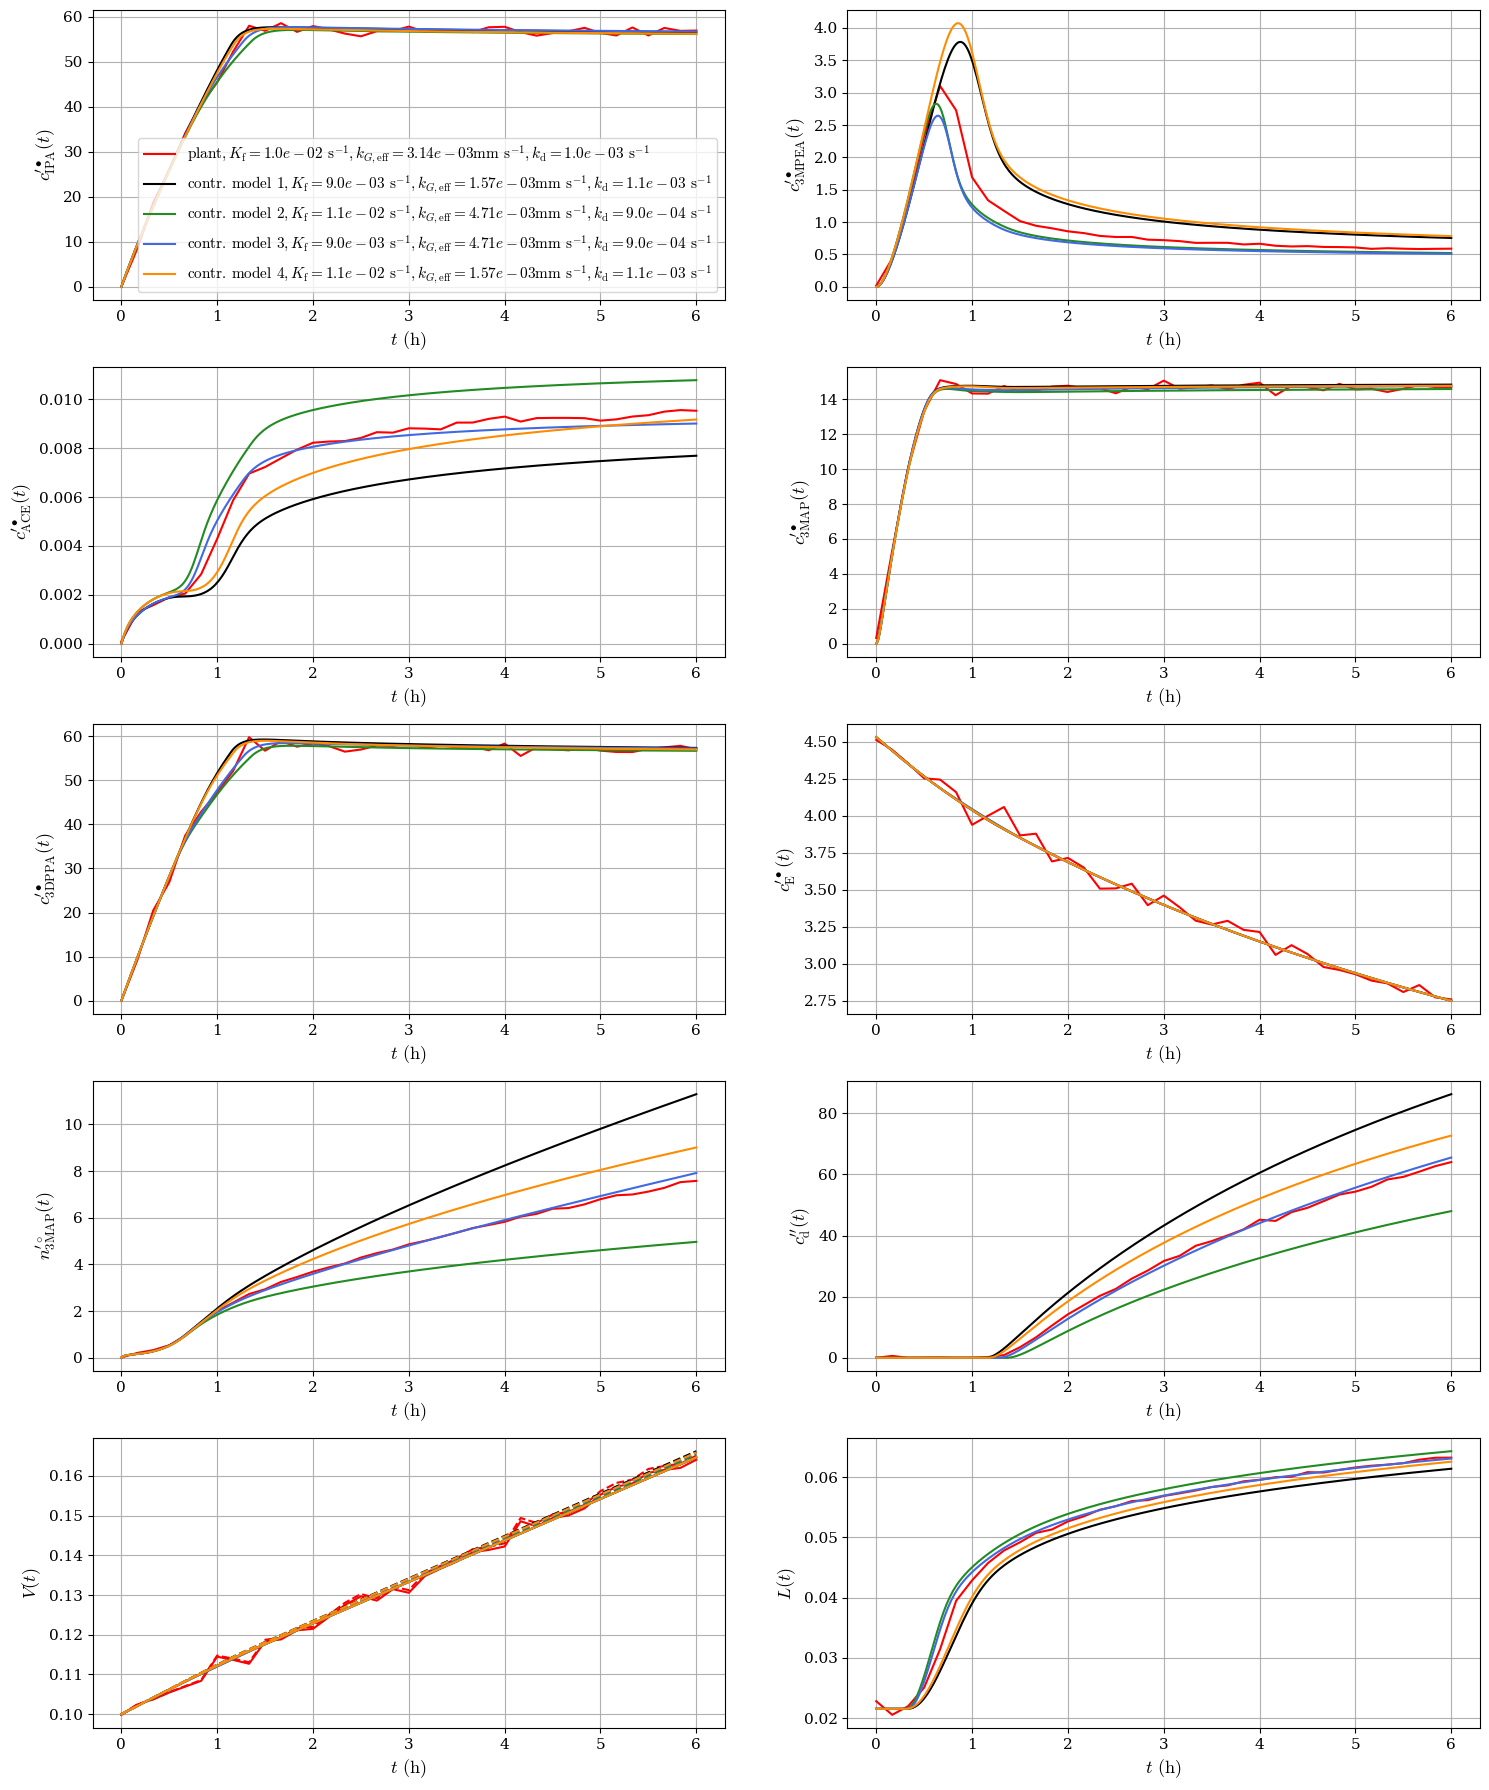

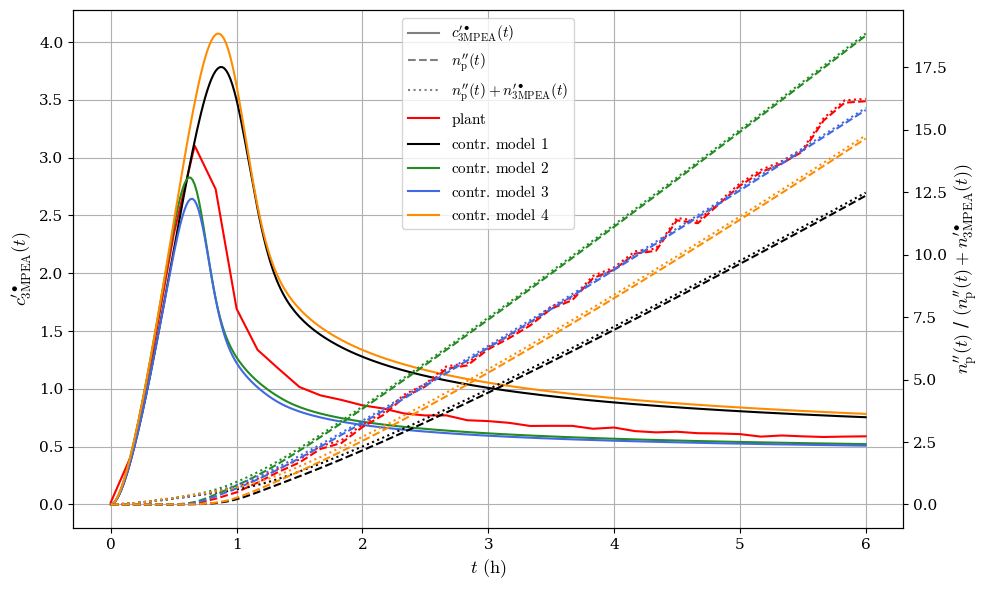

In [2]:
# sampling time of measurements
Ts = 10/60 # every 10 min

# simulation time step (smaller for smoother curves)
dt_sim = 1/60 # every 1 min (6 times smaller than Ts)
n_substeps = int(round(Ts / dt_sim))

# instantiate process model with smaller dt
p_sim = crystallization(t_end=p.t_end, Ts=dt_sim)
p_sim.N_0 = p.N_0
F_int_sim, F_RHS_sim = p_sim.get_model()
p_sim.initialize_noise(std_mess)

# adjust feed inputs for smaller dt
U_feed_sim = np.ones((p_sim.n_u, p_sim.N_sample)) * np.array([0.1, 0.01, 0.1])[:, None]

# simulate nominal model and plant on fine grid
X_plant_sim = p_sim.full_int(F_int=F_int_sim, x0=X0, U=U_feed_sim, para=np.concatenate((para_plant.squeeze(), N0)), p=p_sim)

# generate artificial measurements only every Ts (downsampled from fine simulation)
k_meas = np.arange(0, p_sim.N_sample + 1, n_substeps)
Y_measurements = p_sim.Measurement_Eq(X_plant_sim[:, k_meas], X_lb, k=k_meas, use_noise=1)

# storage for nominal model - simulated with different parameters 
X_nominal_sim = np.zeros((p_sim.n_s, p_sim.N_sample+1, initial_para.shape[1]))

# simulate nominal model ..
for i in range(initial_para.shape[1]): # for a number of different parameters 
    para = 10**initial_para[:,i] # transform parameter from log space
    X_nominal_sim[:,:,i] = p_sim.full_int(F_int=F_int_sim, x0=X0, U=U_feed_sim, para=np.concatenate((para.squeeze(), N0)), p=p_sim)

    # calculate L3 to molar amount on fine grid for plotting smooth curves
    X_nominal_sim[:,:,i] = p_sim.Measurement_Eq(X_nominal_sim[:,:,i], X_lb, k=np.arange(p_sim.N_sample+1), use_noise=0)

# plot results (plotting function will scale time vectors to match lengths)
plot_states_all(t, p, Y_measurements, X_nominal_sim, para_vals1=para_plant, para_vals2=initial_para, save_name='all_states_comparison.png',para_plant=para_plant)
plot_3MPEA(t, p, N0, Y_measurements, X_nominal_sim, para_vals1=para_plant, para_vals2=initial_para, save_name='3MPEA_comparison_figure.png',para_plant=para_plant)
